Top 5 Cuisines Distribution:
Primary Cuisine
North Indian    1278
Chinese          338
Cafe             300
Bakery           274
Fast Food        260
Name: count, dtype: int64

Accuracy: 0.4490

Classification Report:
              precision    recall  f1-score   support

      Bakery       0.29      0.31      0.30        55
        Cafe       0.29      0.25      0.27        60
     Chinese       0.13      0.09      0.11        68
   Fast Food       0.16      0.08      0.10        52
North Indian       0.57      0.70      0.63       255

    accuracy                           0.45       490
   macro avg       0.29      0.28      0.28       490
weighted avg       0.40      0.45      0.42       490



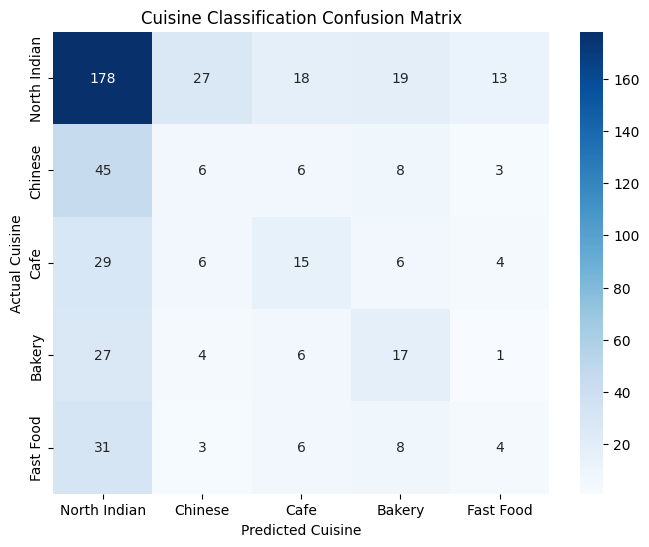

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# 1. Load Data
df = pd.read_csv('Dataset.csv')

# 2. Extract Primary Cuisine
df = df.dropna(subset=['Cuisines'])
df['Primary Cuisine'] = df['Cuisines'].apply(lambda x: x.split(',')[0].strip())

# 3. Filter Top 5 Most Common Cuisines
top_cuisines = df['Primary Cuisine'].value_counts().nlargest(5).index
filtered_df = df[df['Primary Cuisine'].isin(top_cuisines)].copy()

print("Top 5 Cuisines Distribution:")
print(filtered_df['Primary Cuisine'].value_counts())

# 4. Feature Selection & Preprocessing
features = ['Average Cost for two', 'Price range', 'Votes', 'Aggregate rating']
X = filtered_df[features]
y = filtered_df['Primary Cuisine']

# 5. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 6. Model Training (Random Forest)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 7. Evaluation
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"\nAccuracy: {acc:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# 8. Confusion Matrix Visualization
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred, labels=top_cuisines)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=top_cuisines, yticklabels=top_cuisines)
plt.xlabel('Predicted Cuisine')
plt.ylabel('Actual Cuisine')
plt.title('Cuisine Classification Confusion Matrix')
plt.show()